# Personal checker networks for yeast promoters, using PyTorch

This is notebook 2 of the repository, with the second part of the analysis, ran on my personal laptop, with data saved to my own Google Drive. In notebook 1, the published TACO code<sup>1</sup> designed new yeast promoter sequences. Here, **two small networks that I write myself** (a convolutional network and a transformer) learn to predict the expression level of a promoter from its sequence. They are then used as independent **checkers**: they never saw TACO's training, so they can tell whether the designed sequences look good to a second, different model.

A second model is used because, a designed sequence can fool the model it was trained against. Therefore, a checker that was not involved in the design is a fairer test.

### **Step 1: Package Import**

In [1]:
from importlib.metadata import version, PackageNotFoundError
import pathlib
import platform
import random
import urllib.request

import numpy
import pandas
import scipy.stats
import torch
import matplotlib.pyplot as pyplot

# Only exists on Colab. Outside Colab, the name stays empty.
try:
    from google.colab import drive
except ImportError:
    drive = None

print("Python==" + platform.python_version())

packages = ["torch", "numpy", "pandas", "scipy", "matplotlib"]

for package in packages:
    try:
        print(package + "==" + version(package))
    except PackageNotFoundError:
        print(package + ": not installed yet")

Python==3.13.18
torch==2.14.1+cpu
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
matplotlib==3.10.0


### **Step 2: Settings**

All names, folders and numbers are written down in this one cell. If something changes, it is changed here only.

In [2]:
# SETTINGS: the only cell that should need editing.

# The folder in your Google Drive that holds everything big.
drive_dir = "Reinforcement_Learning_for_Promoter_Design"

# Leave this empty on Colab. Only for running the notebook outside Colab: a folder that stands in for the Drive folder.
local_dir = ""

# The table of native yeast promoters. It is downloaded in Step 5 and saved in the Drive folder (the same file that notebook 1 uses in its Step 2).
native_table_url = "https://zenodo.org/records/4436477/files/Native_complex.csv"

# Each native sequence has extra letters (flanks) at both ends. These are removed, as in notebook 1.
flank_length_start = 17
flank_length_end = 13
promoter_length = 80

# The expression value below which a promoter is called weak (from the regLM notebook 02_categorize, as used in notebook 1).
weak_limit = 5.391858

# The split of the native promoters: training, validation and test.
split_fractions = (0.8, 0.1, 0.1)
split_seed = 0

# Training settings.
seeds = [0, 1, 42]
batch_size = 64
maximum_epochs = 30
learning_rate = 0.001

# The TACO result table to be checked, and the weak starting sequences used by TACO (both inside the Drive folder).
taco_results_file = "results/full_run_100_rounds/mbo_0.0_0.0001_complex_mbo_0.csv"
starting_sequences_file = "data/complex/mbo.csv"

# The check for near-identical sequences (Step 14): the limits are numbers of positions at which two sequences differ.
near_identical_limits = [1, 2, 5, 10, 20]
near_identical_limit = 5

### **Step 3: Choose the computing device**

PyTorch can calculate on the graphics card or on the processor. The card is much faster for training, and for handling large processing operations ofcourse, however, this is not needed in this current notebook, like it did in notebook 1. This one is very light in comparison and a normal CPU Runtime will suffice.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


### **Step 4: Connect Google Drive**

Same idea as in notebook 1: Colab erases its files when the session ends, Drive keeps them. The data table, the trained networks and the results live in the Drive folder.

In [4]:
# HELPER FUNCTION
# Connecting Drive on Colab, and returning the project folder in it.
def find_drive_dir():
    if local_dir != "":
        # Only used outside Colab.
        return pathlib.Path(local_dir)
    if drive is None:
        raise RuntimeError("Not running on Colab. Fill in local_dir in Step 2.")
    drive.mount("/content/drive")
    return pathlib.Path("/content/drive/MyDrive") / drive_dir

drive_dir_name = find_drive_dir()
print("Drive project folder:", drive_dir_name)
print("Folder exists:", drive_dir_name.exists())

for notebook_1_file in [taco_results_file, starting_sequences_file]:
    print(notebook_1_file, (drive_dir_name / notebook_1_file).exists())

Mounted at /content/drive
Drive project folder: /content/drive/MyDrive/Reinforcement_Learning_for_Promoter_Design
Folder exists: True
results/full_run_100_rounds/mbo_0.0_0.0001_complex_mbo_0.csv True
data/complex/mbo.csv True


### **Step 5: Load the native promoters**

Downloading the table once from the Drive folder, removing the flanks, keeping only sequences that are exactly 80 letters long and contain only A, C, G and T, and remove sequences that appear twice.

This happens because, the same sequence in the training and the test split would let a network "remember" the answer instead of learning. Removing repeats before the split prevents this.

In [5]:
native_table_path = drive_dir_name / "data" / "complex" / "native_complex.csv"
native_table_path.parent.mkdir(parents=True, exist_ok=True)
urllib.request.urlretrieve(native_table_url, native_table_path)

# The file has one header line, which is skipped. The first three columns are used.
raw_table = pandas.read_csv(native_table_path, usecols=(0, 1, 2), skiprows=1, names=["index", "sequence", "expression"])
print("Rows read:", len(raw_table))

# Removing the flanks.
raw_table["sequence"] = raw_table["sequence"].str[flank_length_start:-flank_length_end]

# Keeping only sequences of the right length that contain only the four letters.
is_valid = (raw_table["sequence"].str.len() == promoter_length) & raw_table["sequence"].str.fullmatch("[ACGT]+")
valid_table = raw_table[is_valid]
print("Rows kept:", len(valid_table))

# Removing repeated sequences (the first one is kept).
promoter_table = valid_table.drop_duplicates(subset="sequence").reset_index(drop=True)
print("Repeated sequences removed:", len(valid_table) - len(promoter_table))
print("Promoters left:", len(promoter_table))
print(promoter_table[["sequence", "expression"]].head(3))

Rows read: 3929
Rows kept: 3929
Repeated sequences removed: 0
Promoters left: 3929
                                            sequence  expression
0  AAAAAAAAAAAGAAAAACAAAGAAAAAGGGGGAATAACACAGCCGC...   13.168816
1  AAAAAAAAAAAGAAAAAGAAACAAAAAGGGGGAATAACACAGCCGC...   13.457919
2  AAAAAAAAAAAGAAAAAGAAAGAAAAAGAGGGAATAACACAGCCGC...   13.855758


### **Step 6: Split, encode and make the loaders**

This step huffles the promoters once with a fixed seed and cut them into training, validation and test parts. Each letter becomes a column of four numbers (**one-hot encoding**: A is 1 0 0 0, C is 0 1 0 0, and so on), so one promoter becomes a table of 4 rows and 80 columns. The expression values are standardised (mean subtracted, then divided by the standard deviation).

The mean and the standard deviation are learned from the **training split only**, so nothing from the validation or test split leaks into training. The test split is used once, at the end. The evaluation loaders are not shuffled.

In [6]:
# HELPER FUNCTION
# Turning a list of sequences into an array of shape (number of sequences, 4, sequence length).
def one_hot_encode(sequences):
    letter_to_row = {"A": 0, "C": 1, "G": 2, "T": 3}
    encoded = numpy.zeros((len(sequences), 4, promoter_length), dtype=numpy.float32)
    for sequence_number, sequence in enumerate(sequences):
        for position, letter in enumerate(sequence):
            encoded[sequence_number, letter_to_row[letter], position] = 1.0
    return encoded

# Shuffling once with a fixed seed, then cutting into three parts.
shuffled_order = numpy.random.default_rng(split_seed).permutation(len(promoter_table))
training_end = int(split_fractions[0] * len(promoter_table))
validation_end = training_end + int(split_fractions[1] * len(promoter_table))
training_table = promoter_table.iloc[shuffled_order[:training_end]]
validation_table = promoter_table.iloc[shuffled_order[training_end:validation_end]]
test_table = promoter_table.iloc[shuffled_order[validation_end:]]
print("Training:", len(training_table), "| Validation:", len(validation_table), "| Test:", len(test_table))

# Learning the standardisation from the training split only.
training_mean = training_table["expression"].mean()
training_standard_deviation = training_table["expression"].std()

def make_tensors(table):
    inputs = torch.tensor(one_hot_encode(table["sequence"].tolist()))
    targets = torch.tensor(((table["expression"] - training_mean) / training_standard_deviation).to_numpy(), dtype=torch.float32)
    return inputs, targets

training_inputs, training_targets = make_tensors(training_table)
validation_inputs, validation_targets = make_tensors(validation_table)
test_inputs, test_targets = make_tensors(test_table)

# The loaders for evaluation are not shuffled. The training loader is made inside the training function (it needs the seed).
validation_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(validation_inputs, validation_targets), batch_size=batch_size, shuffle=False)
test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(test_inputs, test_targets), batch_size=batch_size, shuffle=False)

first_inputs, first_targets = next(iter(torch.utils.data.DataLoader(torch.utils.data.TensorDataset(training_inputs, training_targets), batch_size=batch_size)))
print("One batch: inputs", tuple(first_inputs.shape), "| targets", tuple(first_targets.shape))

Training: 3143 | Validation: 392 | Test: 394
One batch: inputs (64, 4, 80) | targets (64,)


### **Step 7: Look at the data**

This step is producing a histogram of the expression values, with the line below which a promoter counts as weakm, in order to visualise the data for the first time.

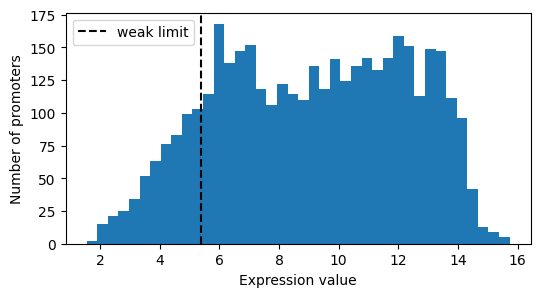

In [7]:
pyplot.figure(figsize=(6, 3))
pyplot.hist(promoter_table["expression"], bins=40)
pyplot.axvline(weak_limit, linestyle="--", color="black", label="weak limit")
pyplot.xlabel("Expression value")
pyplot.ylabel("Number of promoters")
pyplot.legend()
pyplot.show()

### **Step 8: Baseline**

Calculating the baseline here, in order to predict the mean expression of the training split. This happens becasue, a network is only useful if it beats score. A constant prediction has no correlation with anything, so only the **mean absolute error** (the average size of the mistake, in expression units) is reported.

In [8]:
baseline_validation_error = (validation_table["expression"] - training_mean).abs().mean()
print("Baseline mean absolute error on the validation split:", round(float(baseline_validation_error), 4))

Baseline mean absolute error on the validation split: 2.6098


### **Step 9: The two networks**

**Convolutional network:** small filters slide along the sequence and light up when they find a useful short pattern (like a binding site). Two convolution layers, then the values are averaged over the positions and one output layer gives the predicted expression.

**Transformer:** every position looks at every other position (**attention**), so it can combine patterns that are far apart. The four numbers of each letter are first turned into a longer vector, a learned position vector is added (so the network knows where a letter sits), two encoder layers follow, and the average over the positions goes into one output layer.

The number of learnable numbers is worked out with arithmetic below and compared with the count made by PyTorch. Both must agree.

In [9]:
class ConvolutionalChecker(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.first_convolution = torch.nn.Conv1d(4, 64, kernel_size=9, padding=4)
        self.second_convolution = torch.nn.Conv1d(64, 128, kernel_size=9, padding=4)
        self.output_layer = torch.nn.Linear(128, 1)

    def forward(self, inputs):
        hidden = torch.relu(self.first_convolution(inputs))
        hidden = torch.nn.functional.max_pool1d(hidden, 2)
        hidden = torch.relu(self.second_convolution(hidden))
        hidden = hidden.mean(dim=2)
        return self.output_layer(hidden).squeeze(1)


class TransformerChecker(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.input_layer = torch.nn.Linear(4, 64)
        self.position_vectors = torch.nn.Parameter(torch.randn(promoter_length, 64) * 0.02)
        encoder_layer = torch.nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.encoder = torch.nn.TransformerEncoder(encoder_layer, num_layers=2, enable_nested_tensor=False)
        self.output_layer = torch.nn.Linear(64, 1)

    def forward(self, inputs):
        hidden = self.input_layer(inputs.transpose(1, 2)) + self.position_vectors
        hidden = self.encoder(hidden)
        return self.output_layer(hidden.mean(dim=1)).squeeze(1)


# HELPER FUNCTION
# Counting the learnable numbers of a network.
def count_learnable_numbers(network):
    return sum(parameter.numel() for parameter in network.parameters())

network_classes = {"convolutional network": ConvolutionalChecker, "transformer": TransformerChecker}

# The same arithmetic, written out. Each layer has (inputs x outputs [x filter width]) weights plus one bias per output.
by_hand_counts = {
    "convolutional network": (4 * 64 * 9 + 64) + (64 * 128 * 9 + 128) + (128 * 1 + 1),
    # Per encoder layer: attention input 3x(64x64)+3x64, attention output 64x64+64, two feed-forward layers, two normalisations of 2x64.
    "transformer": (4 * 64 + 64) + (80 * 64) + 2 * ((3 * 64 * 64 + 3 * 64) + (64 * 64 + 64) + (64 * 128 + 128) + (128 * 64 + 64) + 2 * (2 * 64)) + (64 * 1 + 1),
}

for network_name, network_class in network_classes.items():
    test_network = network_class()
    output_shape = tuple(test_network(first_inputs).shape)
    counted = count_learnable_numbers(test_network)
    print(network_name, "| output shape:", output_shape, "| counted:", counted, "| by hand:", by_hand_counts[network_name], "| Match:", counted == by_hand_counts[network_name])

convolutional network | output shape: (64,) | counted: 76353 | by hand: 76353 | Match: True
transformer | output shape: (64,) | counted: 72449 | by hand: 72449 | Match: True


### **Step 10: Training, and a first run**

One function trains a network with a fixed seed. After every epoch (one pass through the training split) it measures the mean absolute error on the validation split, and it keeps the weights of the **best epoch**. The seed is set for Python, NumPy, PyTorch and the shuffling of the training loader.

The validation split will be deciding which epoch is kept. The test split is not touched here.

convolutional network
 epoch  training_loss  validation_mean_absolute_error
     1       0.999970                        2.565664
     2       0.915085                        2.413370
     3       0.800403                        2.192984
    28       0.086103                        0.654314
    29       0.083941                        0.692000
    30       0.083973                        0.740123
transformer
 epoch  training_loss  validation_mean_absolute_error
     1       1.024484                        2.586757
     2       0.963931                        2.551076
     3       0.938346                        2.543073
    28       0.125577                        0.863959
    29       0.132524                        1.239838
    30       0.136278                        0.852853


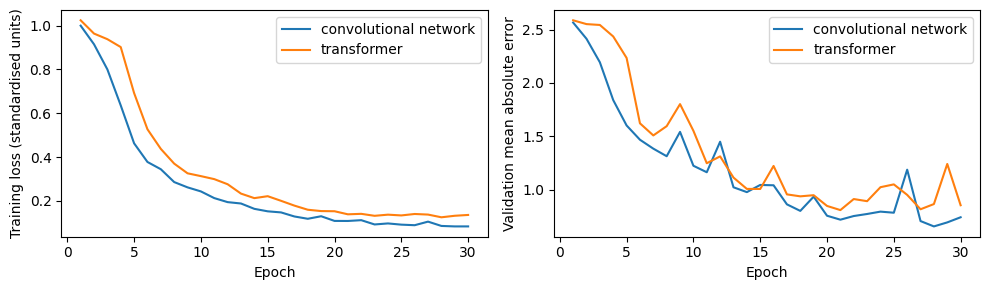

In [10]:
# HELPER FUNCTION
# Setting every random number generator, so that a run can be repeated.
def set_all_seeds(seed):
    random.seed(seed)
    numpy.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# HELPER FUNCTION
# Predicting expression values (in the original units) for a loader. No learning happens here.
def predict_expression(network, loader):
    network.eval()
    predictions = []
    with torch.no_grad():
        for inputs, _ in loader:
            predictions.append(network(inputs.to(device)).cpu())
    standardised = torch.cat(predictions).numpy()
    return standardised * training_standard_deviation + training_mean

# HELPER FUNCTION
# Training one network with one seed. Returns the network at its best epoch and a table of the history.
def train_network(network_class, seed):
    set_all_seeds(seed)
    network = network_class().to(device)
    shuffle_generator = torch.Generator()
    shuffle_generator.manual_seed(seed)
    training_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(training_inputs, training_targets),
        batch_size=batch_size, shuffle=True, generator=shuffle_generator)
    optimiser = torch.optim.Adam(network.parameters(), lr=learning_rate)
    history = []
    best_error = float("inf")
    best_weights = None
    for epoch in range(1, maximum_epochs + 1):
        network.train()
        loss_sum = 0.0
        for inputs, targets in training_loader:
            optimiser.zero_grad()
            loss = torch.nn.functional.mse_loss(network(inputs.to(device)), targets.to(device))
            loss.backward()
            optimiser.step()
            loss_sum += loss.item() * len(inputs)
        validation_error = float(numpy.abs(predict_expression(network, validation_loader) - validation_table["expression"].to_numpy()).mean())
        history.append({"epoch": epoch, "training_loss": loss_sum / len(training_table), "validation_mean_absolute_error": validation_error})
        if validation_error < best_error:
            best_error = validation_error
            best_weights = {name: value.detach().clone() for name, value in network.state_dict().items()}
    network.load_state_dict(best_weights)
    return network, pandas.DataFrame(history)

first_run_histories = {}
for network_name, network_class in network_classes.items():
    _, first_run_histories[network_name] = train_network(network_class, seed=seeds[0])
    history = first_run_histories[network_name]
    print(network_name)
    print(pandas.concat([history.head(3), history.tail(3)]).to_string(index=False))

figure, axes = pyplot.subplots(1, 2, figsize=(10, 3))
for network_name, history in first_run_histories.items():
    axes[0].plot(history["epoch"], history["training_loss"], label=network_name)
    axes[1].plot(history["epoch"], history["validation_mean_absolute_error"], label=network_name)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Training loss (standardised units)"); axes[0].legend()
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation mean absolute error"); axes[1].legend()
pyplot.tight_layout()
pyplot.show()

### **Step 11: Testing and several seeds**

Each network is being trained again with each seed, and the **test split is used once per trained network**. One helper function returns all the metrics: the mean absolute error, the **Pearson correlation** (do predictions rise and fall in a straight-line way with the truth?) and the **Spearman correlation** (do they agree on the order, from lowest to highest?). The table shows the mean and the standard deviation over the seeds, next to the baseline.

The seeds I usually use are 0, 1 and 42, but in this case I will only use 0 to compare with the current TACO results (notebook 1) that had the same seed. Once I run the rest via GPU, then the further comparisons will be added below:

In [11]:
# HELPER FUNCTION
# All metrics for one set of predictions, in the original expression units.
def calculate_metrics(true_values, predicted_values):
    return {
        "mean_absolute_error": float(numpy.abs(predicted_values - true_values).mean()),
        "pearson_correlation": float(scipy.stats.pearsonr(true_values, predicted_values)[0]),
        "spearman_correlation": float(scipy.stats.spearmanr(true_values, predicted_values)[0]),
    }

test_expression = test_table["expression"].to_numpy()
trained_networks = {}
result_rows = []

for network_name, network_class in network_classes.items():
    for seed in seeds:
        network, _ = train_network(network_class, seed=seed)
        trained_networks[(network_name, seed)] = network
        metrics = calculate_metrics(test_expression, predict_expression(network, test_loader))
        result_rows.append({"network": network_name, "seed": seed, **metrics})
        print(result_rows[-1])

results_table = pandas.DataFrame(result_rows)
summary_table = results_table.groupby("network")[["mean_absolute_error", "pearson_correlation", "spearman_correlation"]].agg(["mean", "std"])
print()
print(summary_table.to_string())
print()
print("Baseline mean absolute error on the test split:", round(float(numpy.abs(test_expression - training_mean).mean()), 4))
print("(The standard deviation uses the seeds only; the test split has", len(test_table), "promoters.)")

{'network': 'convolutional network', 'seed': 0, 'mean_absolute_error': 0.6839055652389727, 'pearson_correlation': 0.9554095993577767, 'spearman_correlation': 0.958166141664349}
{'network': 'convolutional network', 'seed': 1, 'mean_absolute_error': 0.7323490876375096, 'pearson_correlation': 0.9546342492147734, 'spearman_correlation': 0.9574060691710126}
{'network': 'convolutional network', 'seed': 42, 'mean_absolute_error': 0.6797634068513162, 'pearson_correlation': 0.9562257234552628, 'spearman_correlation': 0.9599326137071356}
{'network': 'transformer', 'seed': 0, 'mean_absolute_error': 0.8065107534878874, 'pearson_correlation': 0.9389905248683297, 'spearman_correlation': 0.9405691096748421}
{'network': 'transformer', 'seed': 1, 'mean_absolute_error': 0.818022669495677, 'pearson_correlation': 0.9402635160581138, 'spearman_correlation': 0.9397608704811663}
{'network': 'transformer', 'seed': 42, 'mean_absolute_error': 0.7936876608327735, 'pearson_correlation': 0.9397454665709257, 'spear

### **Step 12: Save the trained networks**

The trained weights are saved to the Drive folder so that the checking in Step 13 does not need training again, even after a new session.

In [12]:
saved_networks_folder = drive_dir_name / "results" / "checker_networks"
saved_networks_folder.mkdir(parents=True, exist_ok=True)

for (network_name, seed), network in trained_networks.items():
    torch.save(network.state_dict(), saved_networks_folder / (network_name.replace(" ", "_") + "_seed_" + str(seed) + ".pt"))

print("Saved in:", saved_networks_folder)
for saved_file in sorted(saved_networks_folder.iterdir()):
    print(saved_file.name)

Saved in: /content/drive/MyDrive/Reinforcement_Learning_for_Promoter_Design/results/checker_networks
convolutional_network_seed_0.pt
convolutional_network_seed_1.pt
convolutional_network_seed_42.pt
transformer_seed_0.pt
transformer_seed_1.pt
transformer_seed_42.pt


### **Step 13: Check the sequences designed by TACO**

The designed sequences from the 100-round TACO run (notebook 1) are scored by both of my networks (the average over the seeds). The same is done for the 200 weak starting sequences. For each round, the table shows the mean predicted expression of each network.

TACO improved its own reward model. If my independent networks also predict higher expression for the later rounds, the improvement is not only something the reward model was fooled by. If they disagree, that is worth noting.

**Potential Cautions**
- The weak starting sequences were taken from the same native table, so some of them were in my training split. My networks have seen those rows. Their scores are therefore not a clean test.
- The designed sequences may lie in a part of sequence space that the native promoters do not cover. Predictions there are less reliable. Whether this happens here is not tested here.
- TACO's scores (`true_score`, `oracle_score`) are on a different scale than my networks (expression units), so they are compared by the Spearman correlation only.

Designed sequences: 25600 | Rounds: 100 | Starting sequences: 200
Lengths of designed sequences: [80]

       checked_by_convolutional_network  checked_by_transformer
round                                                          
1                                 9.690                  10.761
2                                 9.812                  10.712
3                                 9.840                  10.534
4                                 9.827                  10.475
5                                10.054                  10.321
6                                 9.836                  10.418
7                                 9.927                  10.449
8                                 9.946                  10.618
9                                10.030                  10.809
10                               10.234                  10.581
11                                9.892                  10.602
12                               10.166                  10.409
1

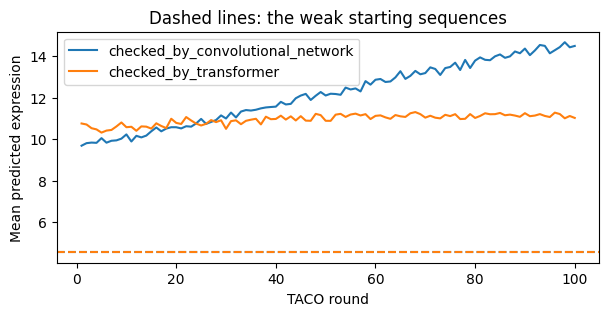

In [13]:
taco_results = pandas.read_csv(drive_dir_name / taco_results_file)
starting_sequences = pandas.read_csv(drive_dir_name / starting_sequences_file)
print("Designed sequences:", len(taco_results), "| Rounds:", taco_results["round"].nunique(), "| Starting sequences:", len(starting_sequences))
print("Lengths of designed sequences:", [int(length) for length in sorted(taco_results["sequence"].str.len().unique())])

# HELPER FUNCTION
# Scoring a list of sequences with one kind of network, averaged over the seeds.
def score_with_checker(network_name, sequences):
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(torch.tensor(one_hot_encode(sequences)), torch.zeros(len(sequences))),
        batch_size=batch_size, shuffle=False)
    return numpy.mean([predict_expression(trained_networks[(network_name, seed)], loader) for seed in seeds], axis=0)

for network_name in network_classes:
    taco_results["checked_by_" + network_name.replace(" ", "_")] = score_with_checker(network_name, taco_results["sequence"].tolist())
    starting_sequences["checked_by_" + network_name.replace(" ", "_")] = score_with_checker(network_name, starting_sequences["sequence"].tolist())

checker_columns = [column for column in taco_results.columns if column.startswith("checked_by_")]
per_round_table = taco_results.groupby("round")[checker_columns].mean()
print()
print(per_round_table.round(3).to_string())
print()
print("Starting sequences, mean prediction:")
print(starting_sequences[checker_columns].mean().round(3).to_string())
print()
for column in checker_columns:
    print("Spearman correlation of", column, "with TACO oracle_score:", round(float(scipy.stats.spearmanr(taco_results[column], taco_results["oracle_score"])[0]), 3))

pyplot.figure(figsize=(7, 3))
for column in checker_columns:
    line = pyplot.plot(per_round_table.index, per_round_table[column], label=column)
    pyplot.axhline(starting_sequences[column].mean(), linestyle="--", color=line[0].get_color())
pyplot.xlabel("TACO round")
pyplot.ylabel("Mean predicted expression")
pyplot.title("Dashed lines: the weak starting sequences")
pyplot.legend()
pyplot.show()

### **Step 14: Check for near-identical sequences between the training and the test split**

The split in Step 6 seems random. If the table contains groups of very similar sequences, a test promoter can have a near copy in the training split, and then the test score can look better than the score on a really new sequence. If the far group scores clearly worse than the near group, the scores of Step 11 are optimistic.

To find out what is going on, for every test promoter, I will be checking the training promoter that differs from it at the fewest positions (the letters are compared position by position; insertions and deletions are not considered). Then the test promoters are split into a **near** group (the closest training promoter differs at `near_identical_limit` positions or fewer) and a **far** group (all others). The metrics are calculated for each group, using the average prediction of the three seeds of each network.


In [14]:
# HELPER FUNCTION
# For every sequence in a one-hot array of shape (number of sequences, 4, length): the smallest number of positions
# at which a training sequence differs from it.
def nearest_training_distance(encoded_sequences):
    training_flat = training_inputs.numpy().reshape(len(training_inputs), -1)
    other_flat = encoded_sequences.numpy().reshape(len(encoded_sequences), -1)
    # With one-hot letters, the product counts the positions that hold the same letter.
    matching_positions = other_flat @ training_flat.T
    return numpy.rint(promoter_length - matching_positions).astype(int).min(axis=1)

test_nearest_distance = nearest_training_distance(test_inputs)
test_count = len(test_nearest_distance)
print("Test sequences:", test_count)
print("Distance to the nearest training sequence: median", int(numpy.median(test_nearest_distance)),
      "| smallest", int(test_nearest_distance.min()), "| largest", int(test_nearest_distance.max()))

for limit in near_identical_limits:
    within_limit = int((test_nearest_distance <= limit).sum())
    print("Nearest training sequence differs at", limit, "or fewer positions:", within_limit, "of", test_count,
          "(" + str(round(100 * within_limit / test_count, 1)) + " percent)")

# The metrics of each network for the near and the far group (average prediction over the seeds).
is_near = test_nearest_distance <= near_identical_limit
group_rows = []
for network_name in network_classes:
    averaged_predictions = numpy.mean(
        [predict_expression(trained_networks[(network_name, seed)], test_loader) for seed in seeds], axis=0)
    for group_name, selected in [("near", is_near), ("far", ~is_near)]:
        if selected.sum() < 10:
            print(network_name, group_name, "group has fewer than 10 sequences; not evaluated.")
            continue
        group_metrics = calculate_metrics(test_expression[selected], averaged_predictions[selected])
        group_rows.append({
            "network": network_name,
            "group": group_name,
            "sequences": int(selected.sum()),
            **group_metrics,
            "baseline_mean_absolute_error": float(numpy.abs(test_expression[selected] - training_mean).mean()),
        })

print()
print("Near group: nearest training sequence differs at", near_identical_limit, "or fewer positions.")
print(pandas.DataFrame(group_rows).round(3).to_string(index=False))

Test sequences: 394
Distance to the nearest training sequence: median 1 | smallest 1 | largest 2
Nearest training sequence differs at 1 or fewer positions: 324 of 394 (82.2 percent)
Nearest training sequence differs at 2 or fewer positions: 394 of 394 (100.0 percent)
Nearest training sequence differs at 5 or fewer positions: 394 of 394 (100.0 percent)
Nearest training sequence differs at 10 or fewer positions: 394 of 394 (100.0 percent)
Nearest training sequence differs at 20 or fewer positions: 394 of 394 (100.0 percent)
convolutional network far group has fewer than 10 sequences; not evaluated.
transformer far group has fewer than 10 sequences; not evaluated.

Near group: nearest training sequence differs at 5 or fewer positions.
              network group  sequences  mean_absolute_error  pearson_correlation  spearman_correlation  baseline_mean_absolute_error
convolutional network  near        394                0.663                0.958                 0.961                       

### **Step 15: Conclusions**

Not written yet. Conclusions are written only after the real outputs of Steps 5 to 13 have been shown and read, and they will contain only what those outputs support. Anything whose cause was not tested is written as "not tested here".

1. **Data.** 3929 native promoters were kept, all different from each other. The random split gives 3143 promoters for training, 392 for validation and 394 for the test split. The baseline (always predicting the training mean) has a mean absolute error of 2.61 on the validation split and 2.75 on the test split.

2. **Both networks learn.** On the test split, the convolutional network reaches a mean absolute error of 0.70 (standard deviation over the three seeds 0.03), a Pearson correlation of 0.955 and a Spearman correlation of 0.959. The transformer reaches 0.81 (0.01), 0.940 and 0.940. The convolutional network is better in all three seeds. The reason is not tested here.

3. **Limit of these numbers.** For every test promoter, a training promoter differs at only 1 or 2 positions (1 position for 82.2 percent of them). The numbers of point 2 therefore describe the prediction of close variants of seen sequences, not of new sequences. A group of test promoters without close training relatives does not exist in this split, so the quality on new sequences was not measured.

4. **TACO's designs (seed 0, 25600 sequences).** Both networks predict about 4.6 for the 200 weak starting sequences and about 10 for the sequences of round 1. Over the 100 rounds, the convolutional network predicts a steady rise (9.69 to 14.50), while the transformer predicts almost no change (10.76 to 11.03). The two checkers therefore agree that the designs lie far above the starting sequences, and disagree about whether the sequences improve during the run.

5. **Agreement with TACO's own checker.** Over all 25600 sequences together, the Spearman correlation with TACO's `oracle_score` is 0.646 for the convolutional network and 0.06 for the transformer. The correlation within single rounds was not calculated.

6. **Cautions.** The designed sequences differ from the weak starting sequences at more than half of the 80 positions (notebook 1). Their distance to the training sequences of the networks was not measured. A mean prediction of 14.5 lies at the upper end of the native values (Step 7), so the predictions may be extrapolations, and they are not expression levels measured in a cell.

7. **Only one TACO run (seed 0) was checked,** so the spread between TACO runs is not known.

8. **Not tested here:** why the transformer does not follow the rise, and how the networks perform on a split by groups of related sequences.

**References**

1. Yang Z, Su B, Cao J, Wen JR. [reference to be verified against the source before it is filled in; see notebook 1, reference 1]